# 05 · Real data vs imputed data, full vs pruned

**Goal.** Measure what the imputation and the pruning change.

* **Country maps.** The PC1–PC2 maps of two configurations are aligned with Procrustes (centred, scaled, rotated to match),
  and we measure how far each country moves. Disparity: 0 = identical maps, 1 = unrelated.
  If imputation drives the movement, countries with more imputed cells should move more.
* **Components.** Tucker's congruence between matching PCs over the shared subindicators (> 0.95 same component, 0.85–0.95 similar, < 0.85 different).
* **Clusters.** ARI between the Ward partitions of every pair of runs, and a country-by-run table with labels matched to A-full · level.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from ilia_explore import data as D, pruning as P, pca as PC, clustering as CL, plots as PL, pipeline as PP

PL.setup_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.precision", 3)

In [2]:
codebook = D.load_codebook()
masked = pd.read_csv(D.PROCESSED / "final_masked_wide.csv", index_col=0)
n_imp = D.imputed_per_country(masked)
tags = [PP.tag(c, m) for c in PP.CONFIGS for m in PP.MODES]
scores = {t: pd.read_csv(D.RESULTS / t / "pca_scores.csv", index_col=0) for t in tags}
loadings = {t: pd.read_csv(D.RESULTS / t / "pca_loadings.csv", index_col=0) for t in tags}
labels = {t: pd.read_csv(D.RESULTS / t / "cluster_labels.csv", index_col=0)["ward"] for t in tags}

## How far countries move

In [3]:
pairs = {
    "A-full → I-full": ("A-full", "I-full"),
    "A-pruned → I-pruned": ("A-pruned", "I-pruned"),
    "A-full → A-pruned": ("A-full", "A-pruned"),
    "I-full → I-pruned": ("I-full", "I-pruned"),
}
disp, disparity, aligned = {}, {}, {}
for mode in PP.MODES:
    for name, (a, b) in pairs.items():
        ra, rb, dis = PC.compare_maps(scores[PP.tag(a, mode)], scores[PP.tag(b, mode)], k=2)
        key = f"{name} · {mode}"
        disp[key] = PC.displacement(ra, rb)
        disparity[key] = dis
        aligned[key] = (ra, rb)
disp = pd.DataFrame(disp)
disp.index.name = "country"
out = D.RESULTS / "comparisons"; out.mkdir(parents=True, exist_ok=True)
disp.join(n_imp).to_csv(out / "procrustes_displacement.csv")
dis = pd.Series(disparity, name="procrustes_disparity").to_frame()
dis["spearman(displacement, n_imputed)"] = [disp[k].corr(n_imp, method="spearman") for k in dis.index]
dis.to_csv(out / "procrustes_disparity.csv")
dis

,procrustes_disparity,"spearman(displacement, n_imputed)"
A-full → I-full · level,0.035,-0.230
A-pruned → I-pruned · level,0.035,0.006
A-full → A-pruned · level,0.029,0.026
I-full → I-pruned · level,0.022,0.125
A-full → I-full · profile,0.224,0.137
A-pruned → I-pruned · profile,0.101,0.134
A-full → A-pruned · profile,0.087,0.304
I-full → I-pruned · profile,0.047,0.125


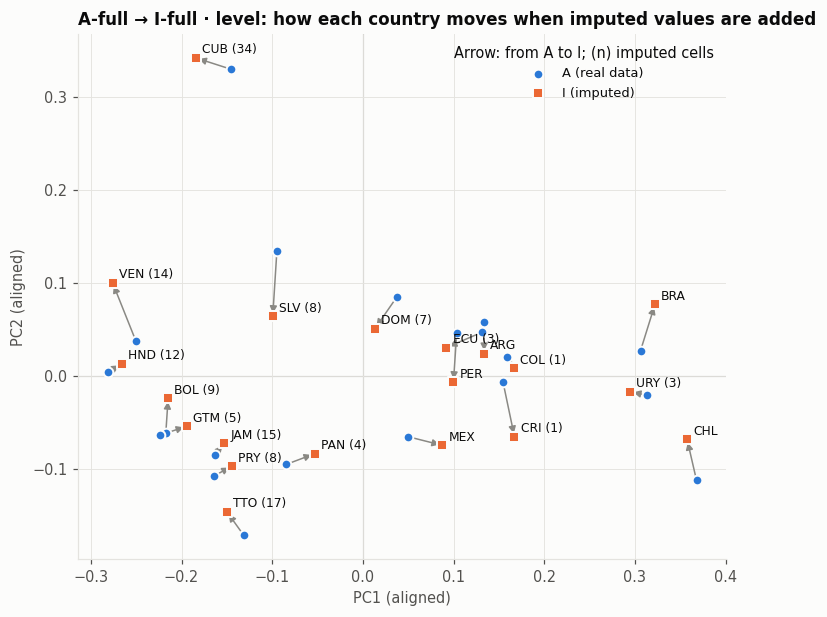

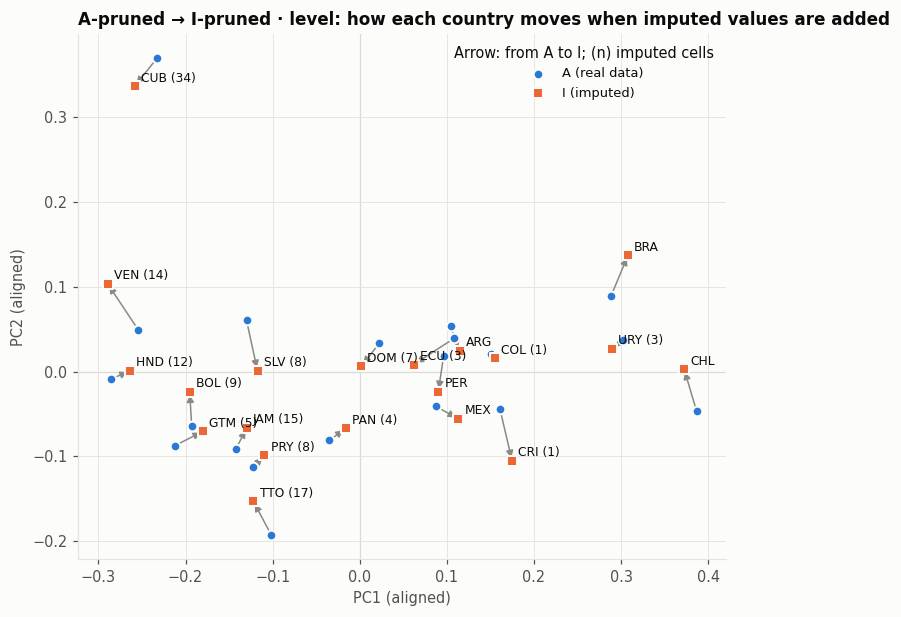

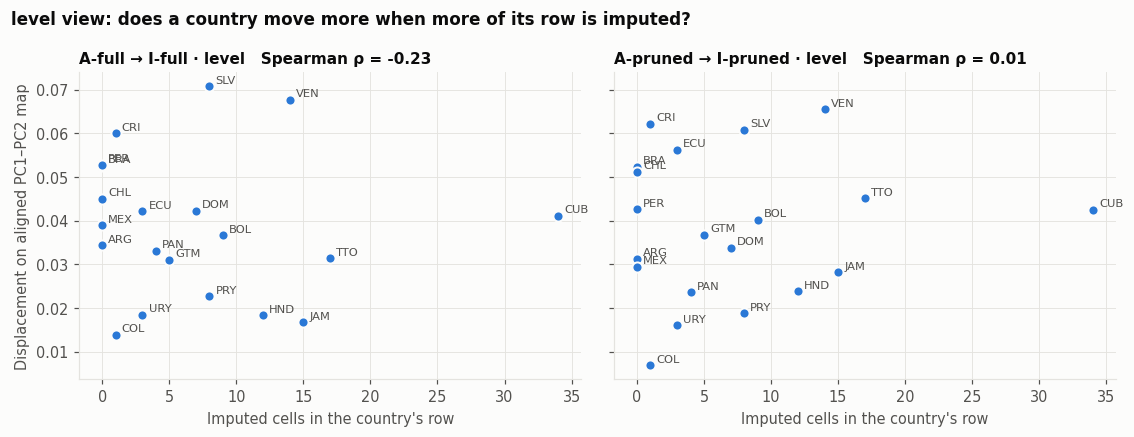

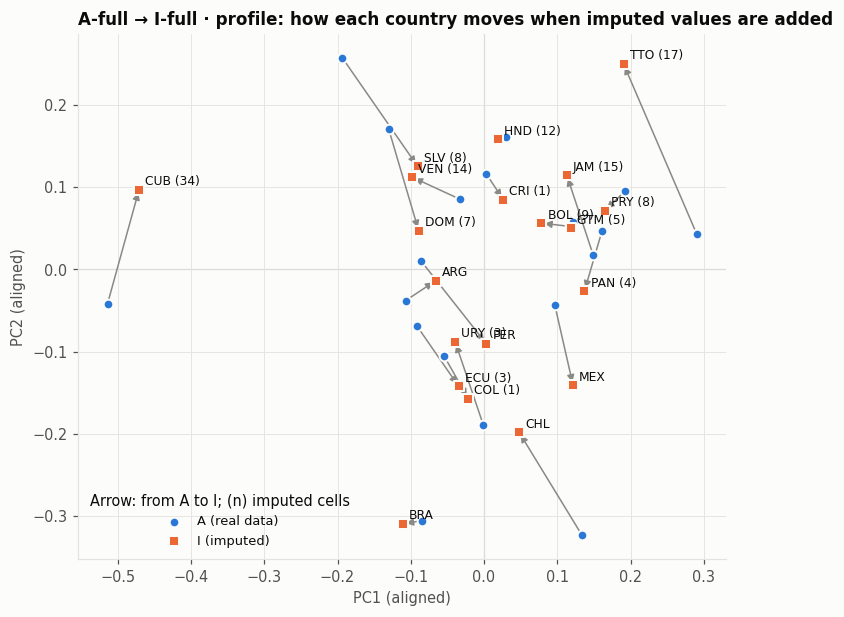

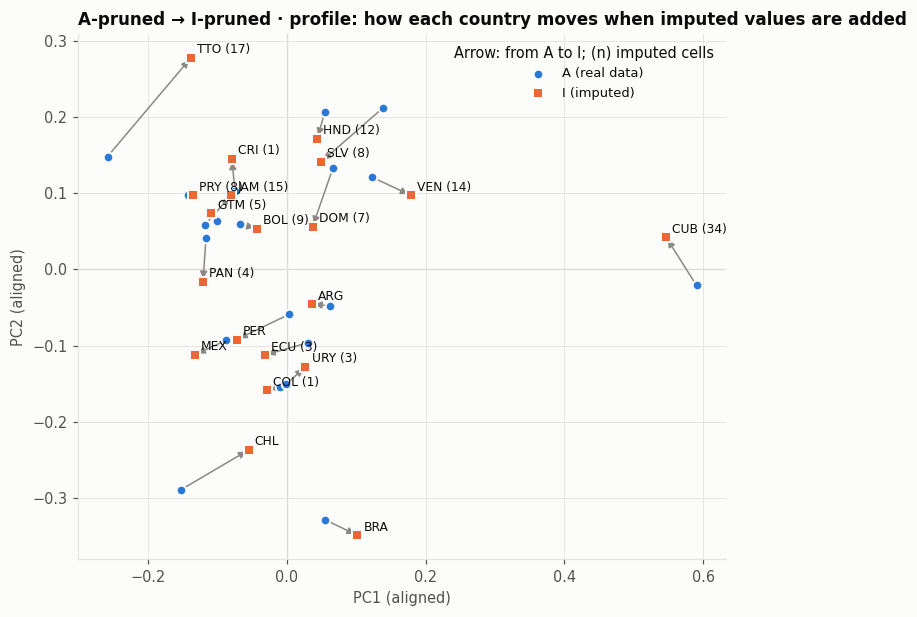

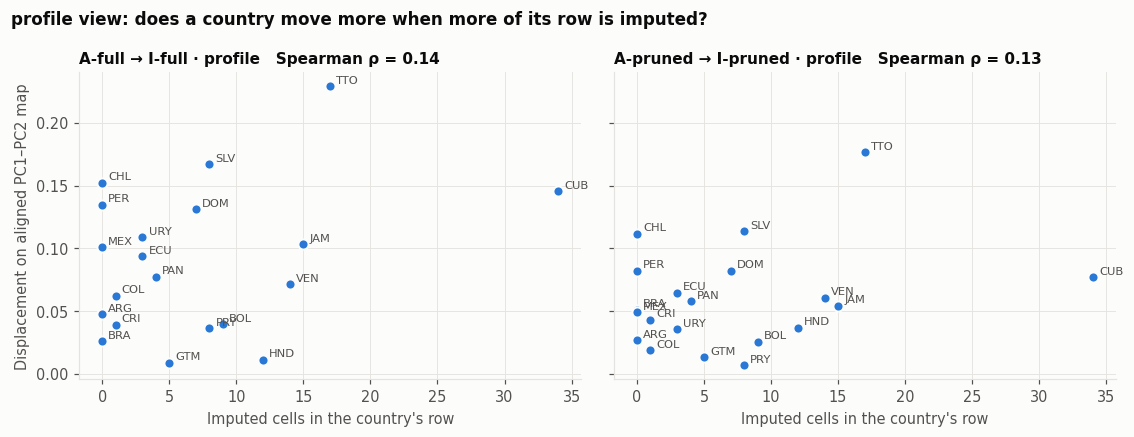

In [4]:
for mode in PP.MODES:
    for name in ["A-full → I-full", "A-pruned → I-pruned"]:
        ra, rb = aligned[f"{name} · {mode}"]
        fig = PL.procrustes_arrows(ra, rb, n_imp, f"{name} · {mode}: how each country moves when imputed values are added")
        PL.save(fig, f"05_procrustes_{name.split(' ')[0]}_{mode}"); plt.show()
    cols = [f"{n} · {mode}" for n in ["A-full → I-full", "A-pruned → I-pruned"]]
    fig = PL.displacement_vs_imputed(disp[cols], n_imp, f"{mode} view: does a country move more when more of its row is imputed?")
    PL.save(fig, f"05_displacement_vs_imputed_{mode}"); plt.show()

In [5]:
disp.assign(n_imputed=n_imp).sort_values("n_imputed", ascending=False).head(8)

,A-full → I-full · level,A-pruned → I-pruned · level,A-full → A-pruned · level,I-full → I-pruned · level,A-full → I-full · profile,A-pruned → I-pruned · profile,A-full → A-pruned · profile,I-full → I-pruned · profile,n_imputed
country,,,,,,,,,
Cuba,0.041,0.042,0.071,0.037,0.146,0.077,0.085,0.020,34
Trinidad y Tobago,0.031,0.045,0.010,0.016,0.229,0.176,0.083,0.041,17
Jamaica,0.017,0.028,0.019,0.029,0.103,0.054,0.043,0.054,15
Venezuela,0.068,0.066,0.042,0.036,0.071,0.060,0.085,0.057,14
Honduras,0.018,0.024,0.023,0.019,0.011,0.037,0.077,0.043,12
Bolivia,0.037,0.040,0.030,0.031,0.039,0.026,0.049,0.041,9
El Salvador,0.071,0.061,0.064,0.053,0.167,0.114,0.090,0.073,8
Paraguay,0.023,0.019,0.033,0.029,0.036,0.007,0.051,0.035,8


## Do the components mean the same thing?

In [6]:
cong = {}
for mode in PP.MODES:
    for name, (a, b) in pairs.items():
        cong[f"{name} · {mode}"] = PC.loading_congruence(loadings[PP.tag(a, mode)], loadings[PP.tag(b, mode)], 4)["tucker_congruence"]
cong = pd.DataFrame(cong).T
cong.to_csv(out / "loading_congruence.csv")
cong

,PC1,PC2,PC3,PC4
A-full → I-full · level,0.998,0.949,0.912,0.912
A-pruned → I-pruned · level,0.999,0.962,0.936,0.867
A-full → A-pruned · level,0.996,0.940,0.916,0.917
I-full → I-pruned · level,0.998,0.955,0.929,0.883
A-full → I-full · profile,0.857,0.521,0.767,0.976
A-pruned → I-pruned · profile,0.798,0.627,0.923,0.924
A-full → A-pruned · profile,0.964,0.949,0.935,0.889
I-full → I-pruned · profile,0.967,0.991,0.944,0.904


## Do the clusters agree?

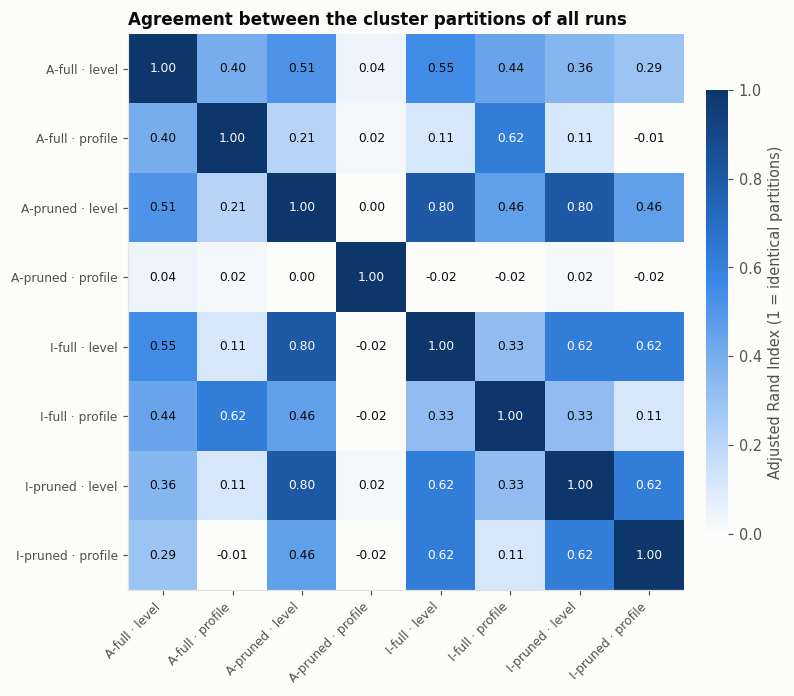

In [7]:
names = [t.replace("_", " · ") for t in tags]
ari = pd.DataFrame([[CL.adjusted_rand_score(labels[a], labels[b]) for b in tags] for a in tags], index=names, columns=names)
ari.to_csv(out / "ari_between_runs.csv")
fig = PL.ari_matrix(ari, "Agreement between the cluster partitions of all runs"); PL.save(fig, "05_ari_between_runs"); plt.show()

Each run above uses its own chosen k, so a k = 4 solution never matches a k = 2 one perfectly. Comparing all runs **at the same k = 2**
isolates the effect of the data and the variable set.

In [8]:
k2 = {t: pd.read_csv(D.RESULTS / t / "ward_membership_by_k.csv", index_col=0)["2"] for t in tags}
level = [t for t in tags if t.endswith("level")]
ari2 = pd.DataFrame([[CL.adjusted_rand_score(k2[a], k2[b]) for b in level] for a in level],
                    index=[t.replace("_", " · ") for t in level], columns=[t.replace("_", " · ") for t in level])
ari2.to_csv(out / "ari_between_runs_k2_level.csv")
upper = {t.replace("_", " · "): sorted(D.iso(k2[t].index[k2[t] == k2[t]["Chile"]])) for t in level}
for t, members in upper.items():
    print(f"{t:18s} upper group: {', '.join(members)}")
ari2

A-full · level     upper group: ARG, BRA, CHL, COL, CRI, ECU, MEX, PER, URY
A-pruned · level   upper group: ARG, BRA, CHL, COL, CRI, DOM, ECU, MEX, PER, URY
I-full · level     upper group: ARG, BRA, CHL, COL, CRI, ECU, MEX, PER, URY
I-pruned · level   upper group: ARG, BRA, CHL, COL, CRI, DOM, ECU, MEX, PAN, PER, URY


,A-full · level,A-pruned · level,I-full · level,I-pruned · level
A-full · level,1.00,0.8,1.00,0.62
A-pruned · level,0.80,1.0,0.80,0.80
I-full · level,1.00,0.8,1.00,0.62
I-pruned · level,0.62,0.8,0.62,1.00


In [9]:
ref = labels["A-full_level"].to_numpy()
matched = pd.DataFrame({t.replace("_", " · "): CL.match_labels(ref, labels[t].to_numpy()) for t in tags},
                       index=D.iso(labels["A-full_level"].index))
matched.insert(0, "n_imputed", n_imp.to_numpy())
matched.to_csv(out / "cluster_labels_matched.csv")
matched.sort_values(["A-full · level", "n_imputed"])

,n_imputed,A-full · level,A-full · profile,A-pruned · level,A-pruned · profile,I-full · level,I-full · profile,I-pruned · level,I-pruned · profile
PAN,4,1,1,1,1,1,1,2,2
GTM,5,1,1,1,1,1,1,1,1
PRY,8,1,1,1,1,1,1,1,1
BOL,9,1,1,1,1,1,1,1,1
HND,12,1,1,1,1,1,1,1,1
VEN,14,1,1,1,1,1,1,1,1
JAM,15,1,1,1,1,1,1,1,1
TTO,17,1,1,1,1,1,1,1,1
ARG,0,2,2,2,1,2,2,2,2
MEX,0,2,1,2,1,2,1,2,2


## Reading the results

**What A → I measures.** The 86 subindicators in A have no imputed cells, so they are identical in I. The difference between A and I is
therefore the effect of *adding the 40 subindicators that have gaps*, new variables and their imputed values together.

* **Level view: imputation barely changes the picture.** The aligned maps are almost the same (Procrustes disparity 0.035),
  and the components keep their meaning (congruence 0.998 for PC1, 0.95–0.96 for PC2).
* **How far a country moves does not depend on how much of its row is imputed** (ρ = −0.23 full, 0.01 pruned).
  Venezuela and El Salvador move most (about 0.07), but Costa Rica, with one imputed cell, moves almost as much. Cuba stays at the strategy extreme.
* **At a common k = 2 the partitions agree:** A-full and I-full are identical (ARI 1.00). The pruned versions differ only on DOM (both) and PAN (I-pruned).
  The full ARI matrix above compares each run at its own chosen k, so A-full (k = 4) looks less similar than it is.
* **Pruning changes even less** (disparity 0.02–0.03 in the level view).
* **Profile view: more sensitive.** The maps differ more (disparity 0.22 full, 0.10 pruned; PC2 congruence 0.52–0.63).
  The 40 added subindicators are mostly FH and IDA, so they shift each country's balance between strategy and capabilities.
  Profile clusters were not supported anyway, so these results remain exploratory.